In [1]:
from knot_repo import available_unknots as unknots #This file holds many examples used in our paper
from drawing_rectangular_diagrams_src import draw_rectangular_diagram as draw
from unknotting_algorithm import *
import random 
import csv
import ast
import concurrent.futures
import time

# 'push_T_simple_unknot' requires gates and snowplows to simplify. It does not unknot with just v1b push and hinge T's and rotating

In [2]:
unknots.show_available_unknots()

['culprit',
 'D28',
 'D43',
 'goeritz',
 'H',
 'J',
 'monster',
 'menasco',
 'ochiai2',
 'ochiai3',
 'ochiai4',
 'joker',
 'partially-simplified-D43',
 'PZ_78',
 'thistletwaite',
 'the-weird-one',
 'tuzun-sikora',
 'zupan',
 'serpent',
 'Lackenby-et-al-hard-unnkot',
 'Hard_Unknot_A',
 'Hard_Unknot_B',
 'Hard_Unknot_C',
 'Hard_Unknot_D',
 'v1b-single-commutation-simple-haken',
 'v1b-simple-haken',
 'haken',
 'push_T_simple_unknot']

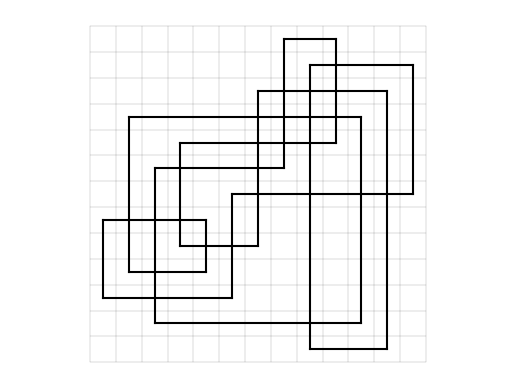

No generalized destabilizations or corner rigidity simplifications.
Checking for Snowplow → Gate simplifications
No generalized destabilizations or corner rigidity simplifications.
Checking for Snowplow → Gate simplifications
No generalized destabilizations or corner rigidity simplifications.
Checking for Snowplow → Gate simplifications
No generalized destabilizations or corner rigidity simplifications.


KeyboardInterrupt: 

In [3]:
#G=unknots.load_unknot('Hard_Unknot_D')
#We turn it into a vertex set by the following:
#V=unknots.grid_to_vertex_set(G)
#10/4/2026 THese EXAMPLEs CAME FROM THE TUZUN SIKORA KNOTS AND WILL NOT UNKNOT WITH THE METHOD BELOW
#V1=[[1, -8], [1, -4], [2, -13], [2, -6], [3, -12], [3, -7], [4, -10], [4, -1], [5, -13], [5, -2], [6, -5], [6, -1], [7, -6], [7, -3], [8, -4], [8, -2], [9, -11], [9, -3], [10, -9], [10, -5], [11, -10], [11, -8], [12, -12], [12, -9], [13, -11], [13, -7]]
V2=[[1, -11], [1, -8], [2, -10], [2, -4], [3, -12], [3, -6], [4, -9], [4, -5], [5, -10], [5, -8], [6, -11], [6, -7], [7, -9], [7, -3], [8, -6], [8, -1], [9, -13], [9, -2], [10, -5], [10, -1], [11, -12], [11, -4], [12, -13], [12, -3], [13, -7], [13, -2]]
#V3=[[1, -14], [1, -2], [2, -13], [2, -11], [3, -12], [3, -1], [4, -15], [4, -3], [5, -6], [5, -4], [6, -9], [6, -5], [7, -10], [7, -8], [8, -9], [8, -2], [9, -13], [9, -7], [10, -14], [10, -11], [11, -12], [11, -4], [12, -15], [12, -6], [13, -8], [13, -3], [14, -7], [14, -1], [15, -10], [15, -5]]
#V4=[[1, -14], [1, -2], [2, -13], [2, -11], [3, -12], [3, -1], [4, -15], [4, -3], [5, -6], [5, -4], [6, -9], [6, -5], [7, -10], [7, -8], [8, -9], [8, -2], [9, -13], [9, -7], [10, -14], [10, -11], [11, -12], [11, -4], [12, -15], [12, -6], [13, -8], [13, -3], [14, -7], [14, -1], [15, -10], [15, -5]] 
draw.draw_rectangular_diagram(V2)
#V=simplify_v1b_T_and_rotate(V2)
V=simplify_v1b_pushT_hingeT_and_rotate(V2)

Checking cyclic permutation: horizontal=0, vertical=0
Checking cyclic permutation: horizontal=0, vertical=1
A valid and essential T has been found:


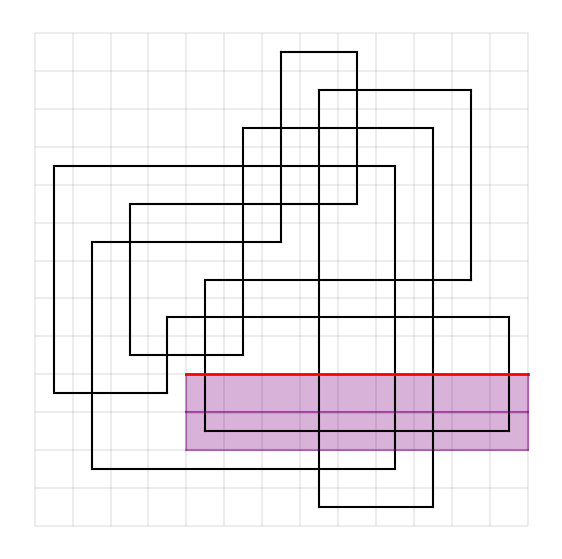

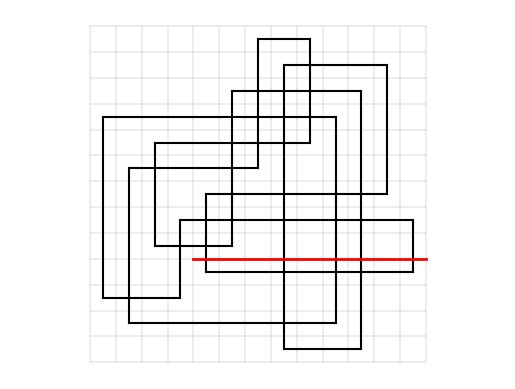

No generalized destabilizations or corner rigidity simplifications.
Checking for Snowplow → Gate simplifications
A valid and essential T has been found:


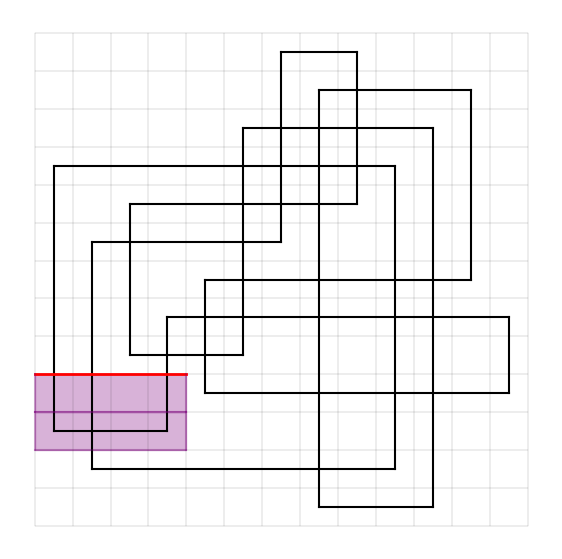

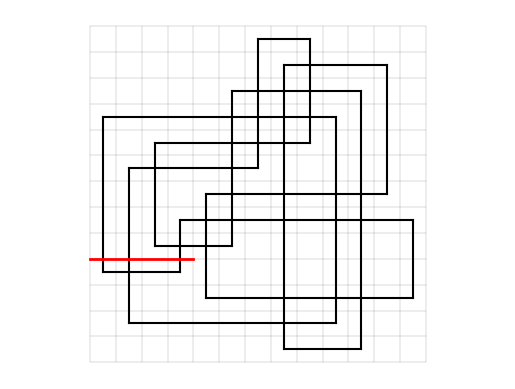

This rectangular diagram has been seen before, attempting to find another valid and essential push T
All remaining T-moves correspond to previously invalid exit disks. Exiting T-move loop.
Checking cyclic permutation: horizontal=0, vertical=2
A valid and essential T has been found:


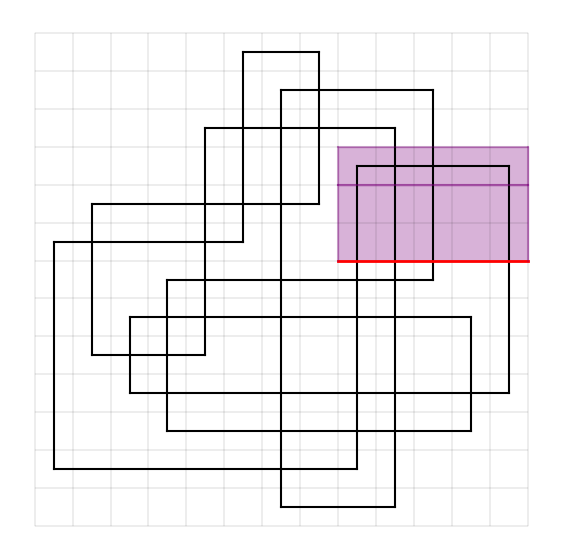

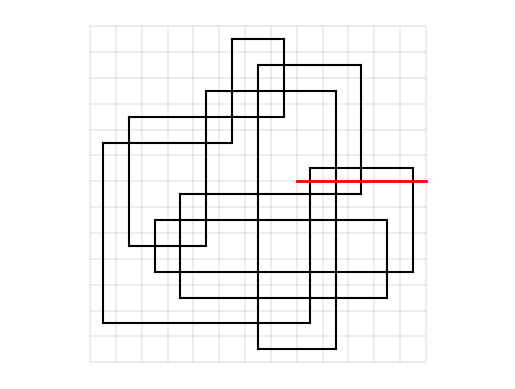

The box below has a SE gate/snowplow simplification


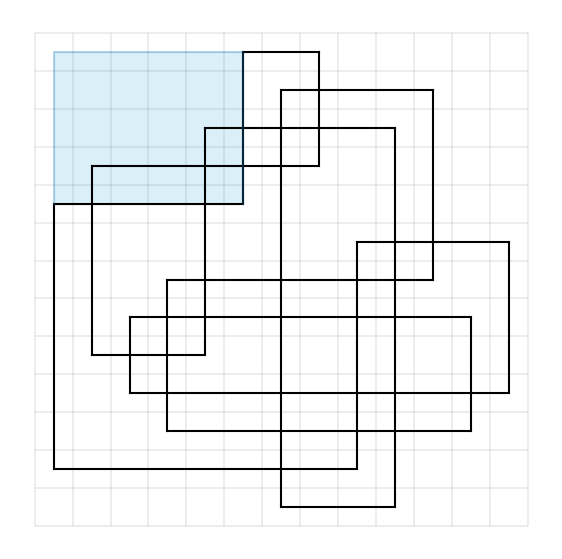

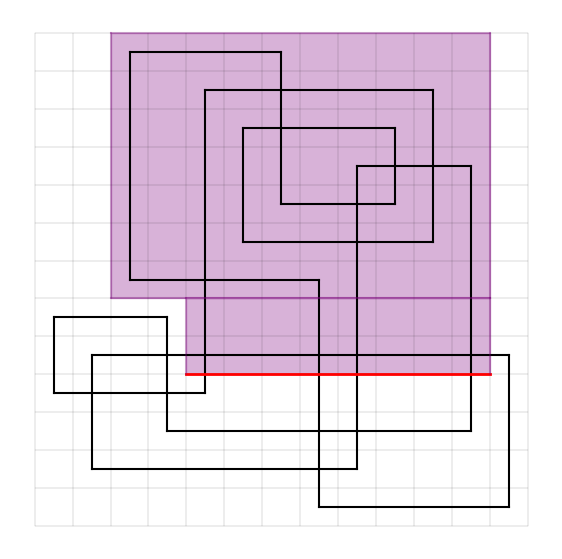

A corner rigid simplification was found.


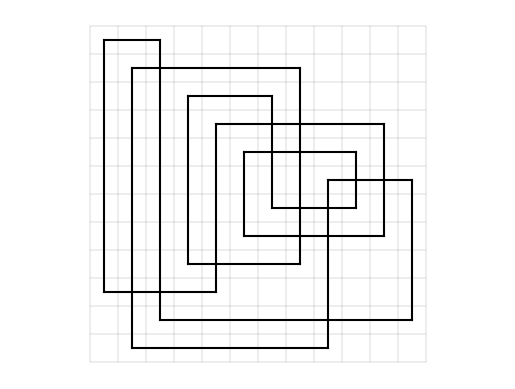

No generalized destabilizations or corner rigidity simplifications.
An upward gate then rightward snowplow move in the following virtual box revealed a type 2 simplification


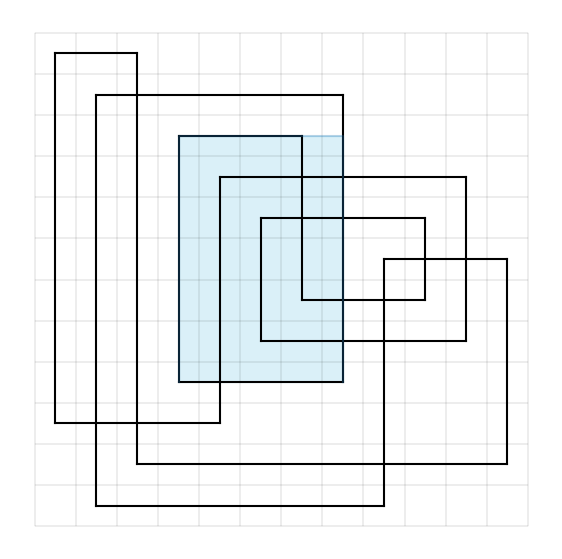

Gate → Snowplow combo modified the diagram.
The box below has a generalized v1b simplification


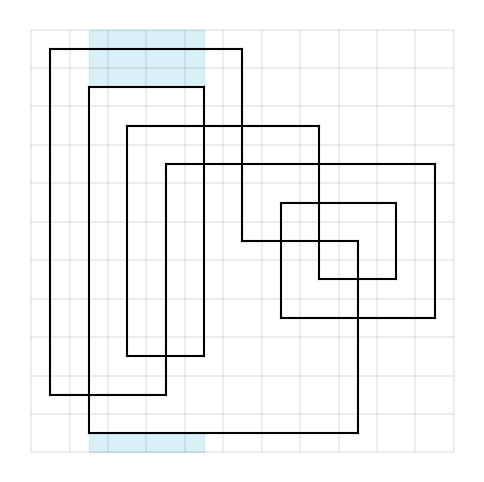

The box below has a generalized v1b simplification


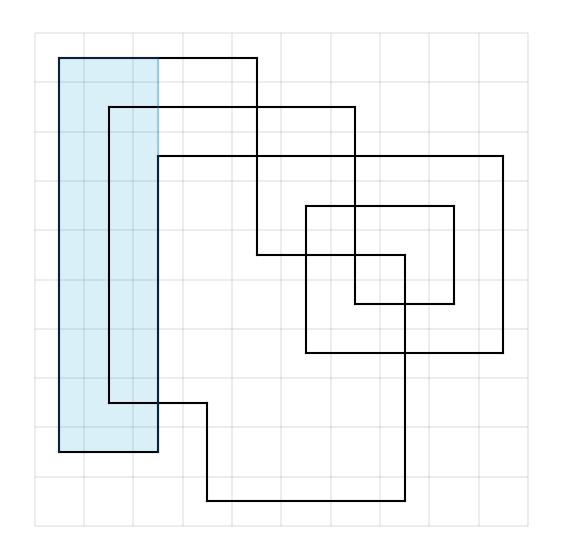

The box below has a generalized v1b simplification


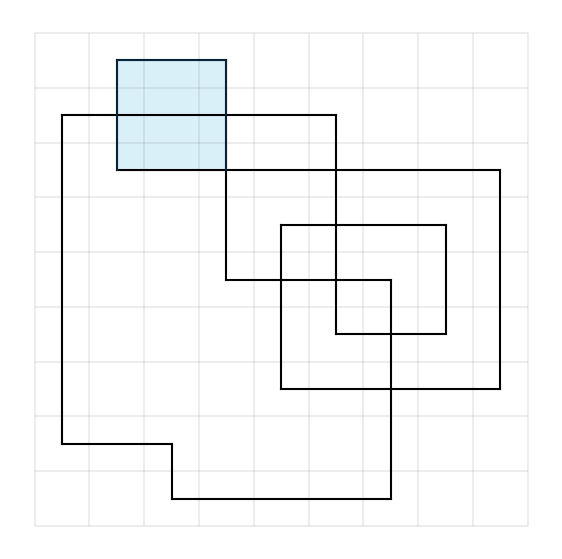

The box below has a generalized v1b simplification


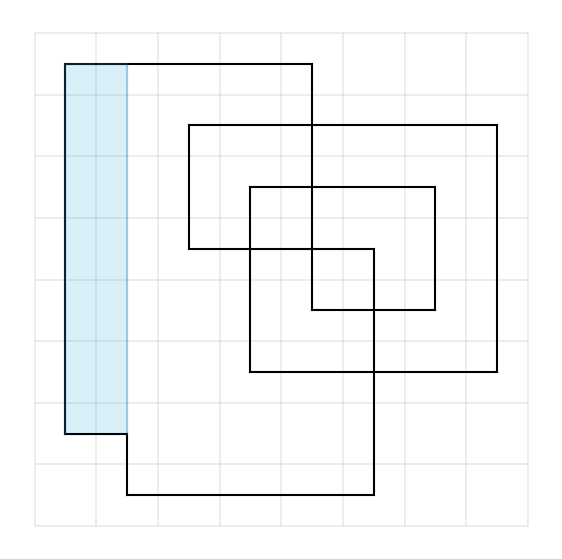

The box below has a generalized v1b simplification


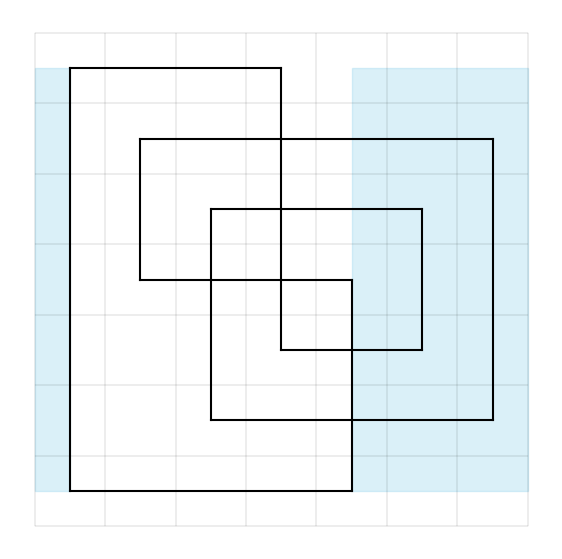

The box below has a generalized v1b simplification


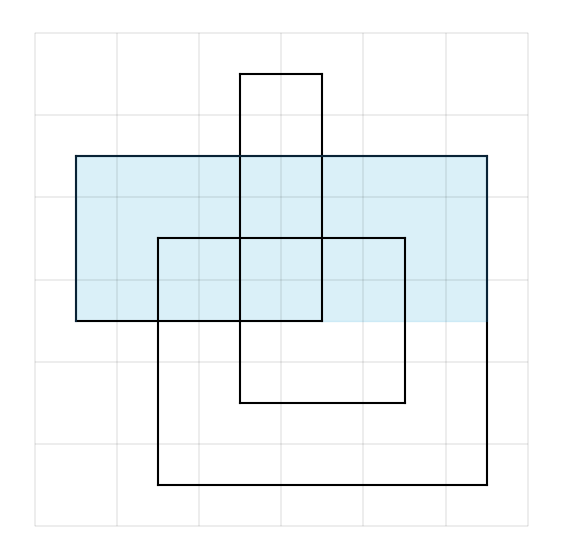

The box below has a generalized v1b simplification


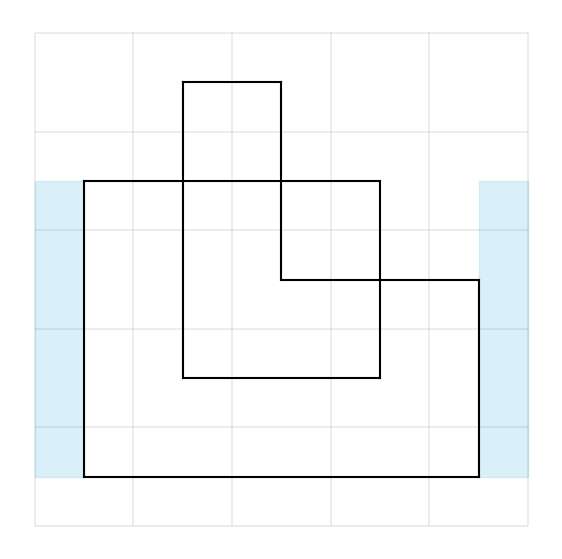

The box below has a generalized v1b simplification


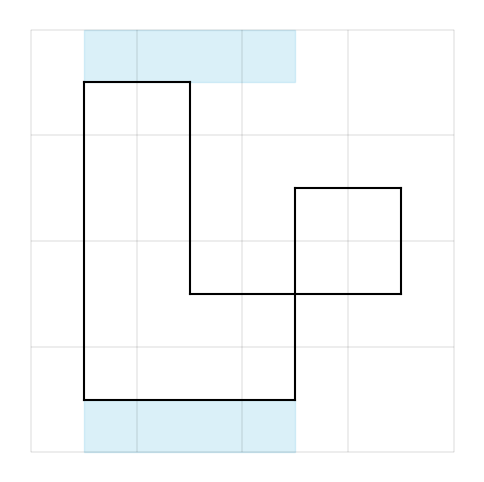

The box below has a generalized v1b simplification


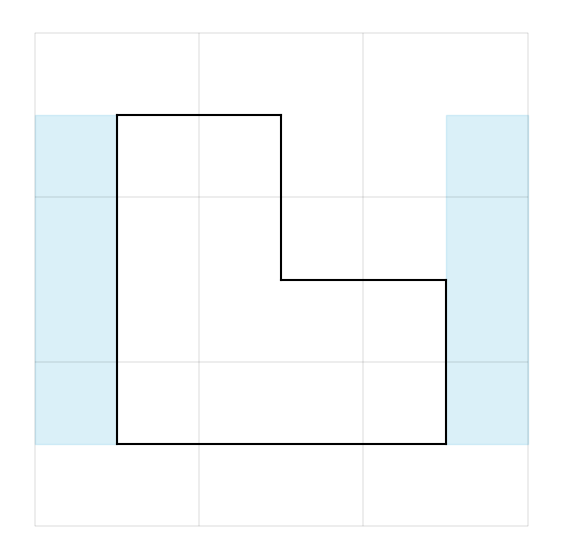

The box below has a generalized v1b simplification


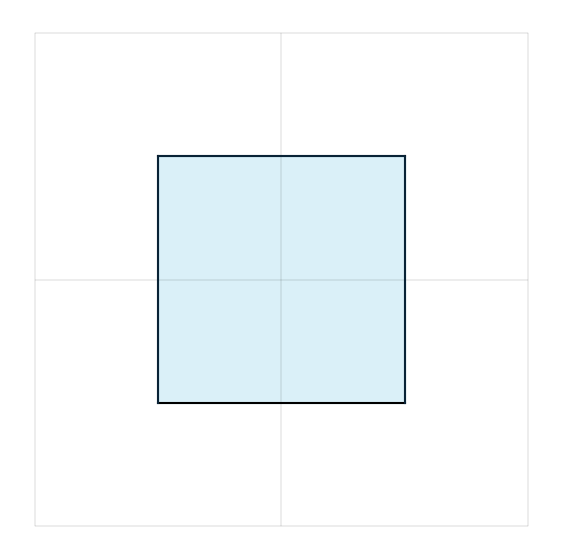

Complexity reduced from 13 to 2


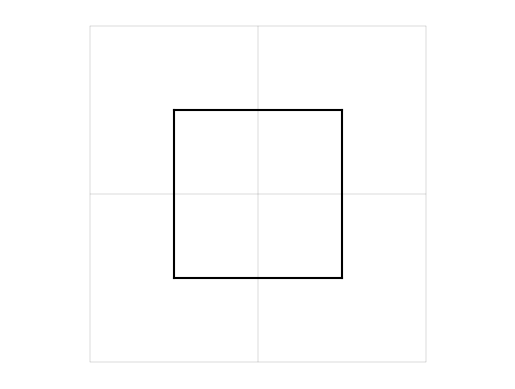

The diagram is unknotted


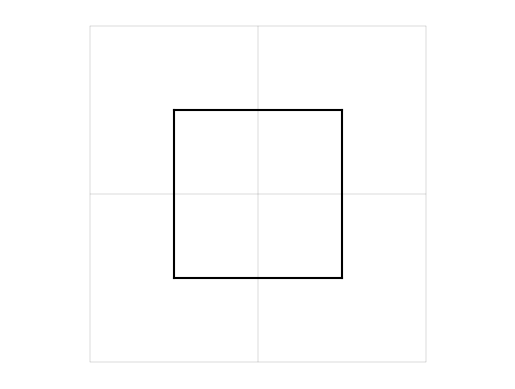

In [4]:
def simplify_across_all_cyclic_permutations1(V):
    rotations = 0

    while True:
        n = len(V) // 2

        # Already the unknot
        if n == 2:
            print("The diagram is unknotted")
            draw_rectangular_diagram(V)
            return V

        reduced = False

        for h in range(n):
            for v in range(n):
                print(f"Checking cyclic permutation: horizontal={h}, vertical={v}")

                V_new,_,_ = perform_push_T_move_and_v1b_reduce(copy.deepcopy(V))
               

                # Success: complexity dropped
                if len(V_new) // 2 < n:
                    print(f"Complexity reduced from {n} to {len(V_new)//2}")
                    draw_rectangular_diagram(V_new)

                    V = V_new
                    rotations = 0      # New diagram: search all orientations again
                    reduced = True
                    break

                # Continue searching from the simplified diagram
                V = vertical_cyclic_permutation_1(
                    V_new, which="left-to-right"
                )

            if reduced:
                break

            # Move to the next horizontal cyclic permutation
            V = horizontal_cyclic_permutation_1(
                V_new, which="top-to-bottom"
            )

        if reduced:
            continue

        # No reduction in this orientation
        if rotations == 3:
            print("No simplifying T-move found.")
            draw_rectangular_diagram(V)
            return V

        print("Attempting rotation")
        V = rotate_vertex_set_90_ccw(V)
        rotations += 1

V2=[[1, -11], [1, -8], [2, -10], [2, -4], [3, -12], [3, -6], [4, -9], [4, -5], [5, -10], [5, -8], [6, -11], [6, -7], [7, -9], [7, -3], [8, -6], [8, -1], [9, -13], [9, -2], [10, -5], [10, -1], [11, -12], [11, -4], [12, -13], [12, -3], [13, -7], [13, -2]]
V=simplify_across_all_cyclic_permutations1(V2)

In [ ]:
def verify_unknot_boolean(V):
    G = vertexset_to_XOGrid(V)
    braid = convert_to_braid(G, optimized='Y', verbose=False)
    try:
        B = Link(braid_closure=braid)
        B.simplify('global')
        if len(B.link_components)==1 and len(B.crossings)==0:
            return True
        elif len(B.link_components)==0:
            print('Could not verify')
            return True  
        else:
            print(B)
            return False
    except ValueError:
        print('Could not verify')
        return True    

In [ ]:
G = vertexset_to_XOGrid(V)
braid = convert_to_braid(G, optimized='Y', verbose=False)
B = Link(braid_closure=braid)
B.simplify('global')
B